## Name : Aastha Pusdekar
## Section : B(B4)
## Roll no. 52
## ML LAB 6

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,precision_score,recall_score,
                             f1_score,classification_report,confusion_matrix)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
from google.colab import files

# This will prompt you to select and upload your file
uploaded = files.upload()

Saving seeds_new (1).csv to seeds_new (1) (3).csv


In [ ]:
df=pd.read_csv("seeds_new (1).csv")

In [ ]:
# Identify the target column dynamically (it is the last column in this dataset)
target_column = df.columns[-1]
print(f"Target column identified as: '{target_column}'")

X = df.drop(columns=[target_column])
y_original = df[target_column]

print("Input Shape :", X.shape)
print("Target Shape :", y_original.shape)

Target column identified as: 'Class (1, 2, 3)'
Input Shape : (210, 7)
Target Shape : (210,)


In [ ]:
y=y_original-1
print("Original Classes :")
print(sorted(y_original.unique()))
print("\nANN encoded classes :")
print(sorted(y.unique()))

Original Classes :
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes :
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_train shape :",X_train.shape[0])
print("X_test shape :",X_test.shape[0])

X_train shape : 168
X_test shape : 42


In [ ]:
scalar = StandardScaler()
scalar.fit(X_train)
X_train = scalar.transform(X_train)
X_test = scalar.transform(X_test)

In [ ]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
loss="sparse_categorical_crossentropy"

In [ ]:
early_stop=EarlyStopping(monitor="val_loss",patience=10,verbose=1,
                         restore_best_weights=True)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    verbose=1,
    validation_split=0.20,
    callbacks=[early_stop]
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 252ms/step - accuracy: 0.3507 - loss: 0.9879 - val_accuracy: 0.5294 - val_loss: 0.9138
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.3955 - loss: 0.9370 - val_accuracy: 0.5294 - val_loss: 0.8655
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.4478 - loss: 0.8930 - val_accuracy: 0.5882 - val_loss: 0.8207
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.5149 - loss: 0.8503 - val_accuracy: 0.7353 - val_loss: 0.7791
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5821 - loss: 0.8108 - val_accuracy: 0.7647 - val_loss: 0.7394
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6418 - loss: 0.7736 - val_accuracy: 0.7647 - val_loss: 0.7045
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.7015 - loss: 0.7393 - val_accuracy: 0.8529 - val_loss: 0.6724
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7388 - loss: 0.7077 - val_accuracy: 0.8824 - val_loss

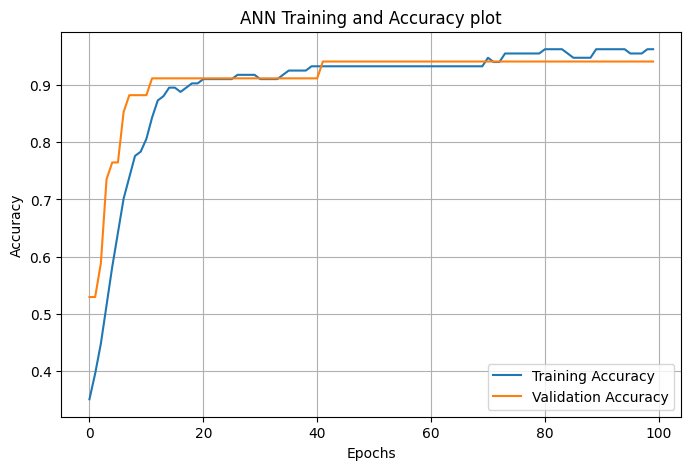

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("ANN Training and Accuracy plot")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss,test_accuracy=model.evaluate(X_test,y_test,verbose=1)
print("Test Loss :",test_loss)
print("Test Accuracy :",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8571 - loss: 0.2998
Test Loss : 0.2998039722442627
Test Accuracy : 0.8571428656578064


In [ ]:
y_prob=model.predict(X_test,verbose=1)
print(y_prob[:5])
y_pred=np.argmax(y_prob,axis=1)
print("Predicted encoded classes:")
print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
[[9.7657186e-01 2.2109000e-03 2.1217214e-02]
 [5.7536911e-02 8.8799314e-04 9.4157505e-01]
 [2.9065752e-01 6.7510426e-01 3.4238216e-02]
 [6.2428336e-03 7.6584853e-05 9.9368054e-01]
 [1.4549127e-03 9.9854082e-01 4.2241354e-06]]
Predicted encoded classes:
[0 2 1 2 1 2 1 1 1 1]


In [ ]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print("Predicted classes:")
print(y_pred_original[:10])

Predicted classes:
[1 3 2 3 2 3 2 2 2 2]


In [ ]:
comparison = pd.DataFrame({"Actual": y_test_original, "Predicted": y_pred_original})
print(comparison.head(10))

     Actual  Predicted
2         1          1
167       3          3
137       2          2
175       3          3
130       2          2
141       3          3
114       2          2
51        1          2
84        2          2
110       2          2


In [ ]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print("Accuracy:",accuracy)

Accuracy: 0.8571428571428571


In [ ]:
precision=precision_score(y_test_original,y_pred_original,average="weighted")
print("precision:",precision)

precision: 0.8823529411764707


In [ ]:
recall=recall_score(y_test_original,y_pred_original,average="weighted")
print("recall:",recall)

recall: 0.8571428571428571


In [ ]:
f1=f1_score(y_test_original,y_pred_original,average="weighted")
print("f1:",f1)

f1: 0.8445747800586509


In [ ]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.57      0.73        14
           2       0.82      1.00      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



In [ ]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]
